# Problema da Mochila 0-1 usando Simulated Annealing

Definição da mochila

- Itens (com seus valores e pesos): gerados de forma aleatória
- Capacidade da mochila: cerca de metade do peso total dos itens


In [1]:
# Parâmetros para a geração da instância aleatória
NUM_ITENS = 20
MAX_PESO_ITEM = 20
MAX_VALOR_ITEM = 100

In [2]:
import random
import math

"""
Classe para representar os itens do Problema da Mochila 0-1
"""
class Item:
    def __init__(self, peso, valor):
        self.peso = peso
        self.valor = valor

    def __repr__(self):
        return f"Item(peso={self.peso}, valor={self.valor})"

"""
Geração de uma instância aleatória para o Problema da Mochila 0-1
"""
def gerar_instancia_aleatoria(num_itens, max_peso, max_valor):
    itens_gerados = []
    for _ in range(num_itens):
        peso = random.randint(1, max_peso)
        valor = random.randint(1, max_valor)
        itens_gerados.append(Item(peso, valor))
    return itens_gerados

"""
Cálculo do valor total e peso de uma solução
"""
def calcular_valor_peso(solucao, itens, capacidade_mochila):
    valor_total = 0
    peso_total = 0
    for i in range(len(solucao)):
        if solucao[i] == 1:
            valor_total += itens[i].valor
            peso_total += itens[i].peso
    if peso_total > capacidade_mochila:
        return 0, peso_total  # ATENÇÃO: retorna 0 de valor se a capacidade for excedida
    return valor_total, peso_total

In [3]:
# Geração da lista de itens
print(f"\n--- Geração de uma instância aleatória do Problema da Mochila 0-1 com {NUM_ITENS} itens ---")
itens = gerar_instancia_aleatoria(NUM_ITENS, MAX_PESO_ITEM, MAX_VALOR_ITEM)

# Definição da capacidade da mochila: cerca de metade do peso total dos itens
peso_total_itens = sum(item.peso for item in itens)
capacidade_mochila = peso_total_itens // 2

# Impressão da capacidade da mochila
print(f"Capacidade da mochila: {capacidade_mochila}")

# Impressão da lista de itens gerada de forma aleatória - debugging
#print("Lista de Itens Gerados Aleatoriamente:")
#for i, item in enumerate(itens):
#    print(f"Item {i+1}: Peso={item.peso}, Valor={item.valor}")



--- Geração de uma instância aleatória do Problema da Mochila 0-1 com 20 itens ---
Capacidade da mochila: 133


Resolução do problema usando programação diâmica (solução ótima)

In [4]:
"""
  Programação Dinâmica para determinar a solução ótima da instância gerada: implementação clássica via as relações de recorrência da Mochila 0-1, conforme material disponibilizado
"""
def programacao_dinamica(itens, capacidade):
    n = len(itens)
    dp = [[0 for _ in range(capacidade + 1)] for _ in range(n + 1)]
    for i in range(1, n + 1):
        item = itens[i-1]
        for w in range(1, capacidade + 1):
            if item.peso <= w:
                dp[i][w] = max(item.valor + dp[i-1][w - item.peso], dp[i-1][w])
            else:
                dp[i][w] = dp[i-1][w]

    # --- Início da Reconstrução da Solução---
    valor_maximo = dp[n][capacidade]

    # 1. Cria um array de zeros com o tamanho da lista de itens
    selecao = [0] * n

    w = capacidade
    for i in range(n, 0, -1):
        # Se o valor mudou da linha de cima para a atual, o item foi incluído
        if dp[i][w] != dp[i-1][w]:
            # 2. Marca a posição do item como 1
            selecao[i-1] = 1
            # E atualiza a capacidade restante
            w -= itens[i-1].peso

    return valor_maximo, selecao

Executar Programação Dinâmica para a instância gerada

In [5]:
print("\n--- Programação Dinâmica ---")
valor_pd, melhor_solucao_pd  = programacao_dinamica(itens, capacidade_mochila)
print(f"Valor Ótimo: {valor_pd}")
print(f"Solução Ótima: {melhor_solucao_pd}")


--- Programação Dinâmica ---
Valor Ótimo: 627
Solução Ótima: [0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0]


# Simulated Annealing

A inspiração para o Simulated Annealing (SA) vem do processo de recozimento de metais na metalurgia. Nele, um metal é aquecido a uma temperatura muito alta e depois é resfriado bem lentamente. No início, as partículas do metal têm energia suficiente para se mover livremente. À medida que a temperatura diminui, as partículas se estabilizam em um estado de baixa energia.

SA para o problema da mochila:

-  Solução: um subconjunto de itens, representada por um array de 0s e 1s, em que 1 significa que o item está na mochila e 0 significa que não está.

-  Valor de uma solução: somatório dos valores dos itens que estão em 1 na solução.

-  Temperatura: parâmetro que controla a probabilidade de aceitação de uma solução pior do que a solução corrente para promover diversificação.
               No início, a temperatura é alta, e temos alta probabilidade de aceitar soluções piores para explorar o espaço de busca.
               Conforme a temperatura decai, essa probabilidade diminui.

-  Vizinhança: um vizinho é uma nova solução gerada a partir da solução atual através de uma vizinhança N1 (troca de 1 bit)
              Sorteamos um item e, se ele está na solução (vale 1) então ele sai da solução (passa a valer 0); e vice-versa.

In [6]:
# Parâmetros para o Simulated Annealing
temperatura_inicial = 1000
temperatura_minima = 1
fator_resfriamento = 0.9
iteracoes_por_temperatura = 100 # Experimente diferentes valores aqui, p.ex., entre 50 e 500, para ver como esse fator possui forte impacto na qualidade da solução obtida (gap)

Código:

In [7]:
"""
Geração de uma solução inicial viável e aleatória: embaralha os índices e vai colocando os itens na mochila enquanto eles couberem
"""
def gerar_solucao_inicial(itens):
    solucao = [0] * len(itens)
    peso_atual = 0
    indices = list(range(len(itens)))
    random.shuffle(indices)

    for i in indices:
        if peso_atual + itens[i].peso <= capacidade_mochila:
            solucao[i] = 1
            peso_atual += itens[i].peso
    return solucao

"""
  Geração de uma solução vizinha a partir da solução atual - sorteia uma posição idx da solução atual e:
    Se o item não pertencer à solução atual (se ele valer 0), testa se ele pode ser inserido na mochila. Se puder, ele vira 1 na solução.
    Caso contrário (item não pertence à solução atual), o item é removido da solução (ele vira 0 na solução)
"""
def gerar_vizinho(solucao, itens, capacidade_mochila):
    vizinho = list(solucao)
    while True:
        idx = random.randint(0, len(itens) - 1)

        if vizinho[idx] == 0:
            if calcular_valor_peso(vizinho, itens, capacidade_mochila)[1] + itens[idx].peso <= capacidade_mochila:
                vizinho[idx] = 1
                return vizinho
        else:
            vizinho[idx] = 0
            return vizinho

"""
Algoritmo de Simulated Annealing (SA)
--------- -- --------- ---------  --
"""
def simulated_annealing_mochila(itens, capacidade_mochila, temperatura_inicial, temperatura_minima, fator_resfriamento, iteracoes_por_temperatura):
    # Geração da Solução Inicial para a instância fornecida/gerada aleatoriamente
    solucao_atual = gerar_solucao_inicial(itens)
    valor_inicial, peso_inicial = calcular_valor_peso(solucao_atual, itens, capacidade_mochila)
    # Demais inicializações
    melhor_solucao = list(solucao_atual)
    melhor_valor = valor_inicial
    temperatura = temperatura_inicial
    iteracao_global = 0 # utilizado para controlar em quais iterações temos melhorias
    print("\n--- Solução Inicial ---")
    print(f"Solução Inicial: {melhor_solucao}")
    print(f"Valor Inicial: {melhor_valor}")

    # Loop externo: Resfriamento da temperatura
    print("\n--- Iterações SA ---")
    list_melhor_valor = {0: valor_inicial}
    list_valor_vizinho = {}
    list_temperature = {}
    while temperatura > temperatura_minima:
        # Loop interno: Iterações por nível de temperatura (Iterações de Metropolis)
        for _ in range(iteracoes_por_temperatura):
            iteracao_global += 1

            solucao_vizinha = gerar_vizinho(solucao_atual, itens, capacidade_mochila)
            valor_atual, _ = calcular_valor_peso(solucao_atual, itens, capacidade_mochila)
            valor_vizinho, _ = calcular_valor_peso(solucao_vizinha, itens, capacidade_mochila)

            list_valor_vizinho[iteracao_global] = valor_vizinho
            list_temperature[iteracao_global] = temperatura

            delta_valor = valor_vizinho - valor_atual

            if delta_valor > 0:
                solucao_atual = solucao_vizinha
                if valor_vizinho > melhor_valor:
                    melhor_solucao = list(solucao_vizinha)
                    melhor_valor = valor_vizinho
                    list_melhor_valor[iteracao_global] = melhor_valor
                    # IMPRIME UMA NOVA MELHOR SOLUÇÃO QUANDO ELA É ENCONTRADA
                    print(f"Iteração {iteracao_global}, Temperatura {temperatura:.2f}: valor = {melhor_valor}, solução = {melhor_solucao}")
            else:
                probabilidade = math.exp(delta_valor / temperatura)
                if random.uniform(0, 1) < probabilidade:
                    solucao_atual = solucao_vizinha

        # Resfriamento da temperatura acontece apenas aqui, no loop externo
        temperatura *= fator_resfriamento

    dict_output = {'valor_vizinho': list_valor_vizinho,
                   'melhor_valor': list_melhor_valor,
                   'temperature': list_temperature}
    return melhor_solucao, dict_output

# Execução do SA

In [8]:
# Impressão dos parâmetros para o SA
print("\n--- Parâmetros do SA ---")
print(f"Temperatura_inicial: {temperatura_inicial}")
print(f"Temperatura_final ou mínima: {temperatura_minima}")
print(f"Fator de resfriamento: {fator_resfriamento}")
print(f"Iterações por temperatura (iterações de Metropolis): {iteracoes_por_temperatura}")

print("\n --- Programação Dinâmica ---")
print(f"Valor Ótimo (PD): {valor_pd}")
print(f"Solução Ótima (PD): {melhor_solucao_pd}")

# Execução do algoritmo SA para a Mochila 0-1
melhor_solucao_encontrada, output = simulated_annealing_mochila(itens,
                                                                capacidade_mochila,
                                                                temperatura_inicial,
                                                                temperatura_minima,
                                                                fator_resfriamento,
                                                                iteracoes_por_temperatura)
valor_final, peso_final = calcular_valor_peso(melhor_solucao_encontrada,
                                              itens,
                                              capacidade_mochila)

# Cálculo do Gap
if valor_pd > 0:
  gap = ((valor_pd - valor_final) / valor_pd) * 100
else:
  print("\n--- !!!HÁ ALGO ERRADO: valor_ProgDin <= 0!!! ---")

print("\n--- Resultado Final ---")
print(f"Melhor Solução Encontrada: {melhor_solucao_encontrada}")
print(f"Valor Total: {valor_final}  (gap = {gap:.2f}%)")
print(f"Peso Total: {peso_final}")
print(f"Capacidade da Mochila: {capacidade_mochila}")


--- Parâmetros do SA ---
Temperatura_inicial: 1000
Temperatura_final ou mínima: 1
Fator de resfriamento: 0.9
Iterações por temperatura (iterações de Metropolis): 100

 --- Programação Dinâmica ---
Valor Ótimo (PD): 627
Solução Ótima (PD): [0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0]

--- Solução Inicial ---
Solução Inicial: [1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0]
Valor Inicial: 393

--- Iterações SA ---
Iteração 8, Temperatura 1000.00: valor = 439, solução = [0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0]
Iteração 34, Temperatura 1000.00: valor = 452, solução = [0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1]
Iteração 70, Temperatura 1000.00: valor = 524, solução = [0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0]
Iteração 163, Temperatura 900.00: valor = 543, solução = [0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0]
Iteração 1170, Temperatura 313.81: valor = 550, solução = [0, 1, 1, 0, 1, 0, 1, 1, 0

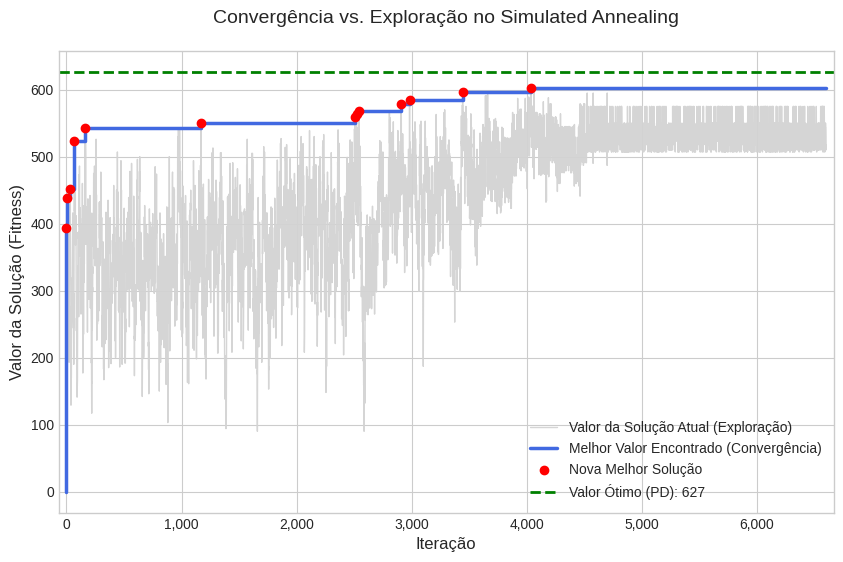

In [9]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Seus dados de melhora (convergência)
dados_melhora = output['melhor_valor']
valores_atuais = output['valor_vizinho'].values()
total_iteracoes = len(valores_atuais)

# Preparação dos dados para o gráfico de escada (melhor valor)
iteracoes_plot = [0]
valores_plot = [0]
valor_anterior = 0
for iteracao, valor in sorted(dados_melhora.items()):
    iteracoes_plot.append(iteracao)
    valores_plot.append(valor_anterior)
    iteracoes_plot.append(iteracao)
    valores_plot.append(valor)
    valor_anterior = valor
iteracoes_plot.append(total_iteracoes)
valores_plot.append(valor_anterior)

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Plotar o valor atual (oscilatório) de forma sutil
ax.plot(
    range(total_iteracoes),
    valores_atuais,
    label='Valor da Solução Atual (Exploração)',
    color='lightgray',
    linewidth=1.0,
    alpha=0.95
)

# 2. Plotar o melhor valor (convergência) de forma destacada
ax.plot(
    iteracoes_plot,
    valores_plot,
    drawstyle='steps-post',
    label='Melhor Valor Encontrado (Convergência)',
    color='royalblue',
    linewidth=2.5
)

# Pontos de melhora
ax.scatter(
    list(dados_melhora.keys()),
    list(dados_melhora.values()),
    color='red',
    zorder=5,
    label='Nova Melhor Solução'
)

ax.axhline(
    y=valor_pd,
    color='green',
    linestyle='--',
    linewidth=2,
    label=f'Valor Ótimo (PD): {valor_pd}'
)

# Configurações do gráfico
ax.set_title('Convergência vs. Exploração no Simulated Annealing', fontsize=14, pad=20)
ax.set_xlabel('Iteração', fontsize=12)
ax.set_ylabel('Valor da Solução (Fitness)', fontsize=12)
ax.legend(loc='lower right')
ax.margins(x=0.01, y=0.05)

# Formatação dos eixos
ax.get_xaxis().set_major_formatter(mticker.FuncFormatter(lambda x, p: format(int(x), ',')))
ax.get_yaxis().set_major_formatter(mticker.FuncFormatter(lambda y, p: format(int(y), ',')))

Text(0, 0.5, 'Temperatura')

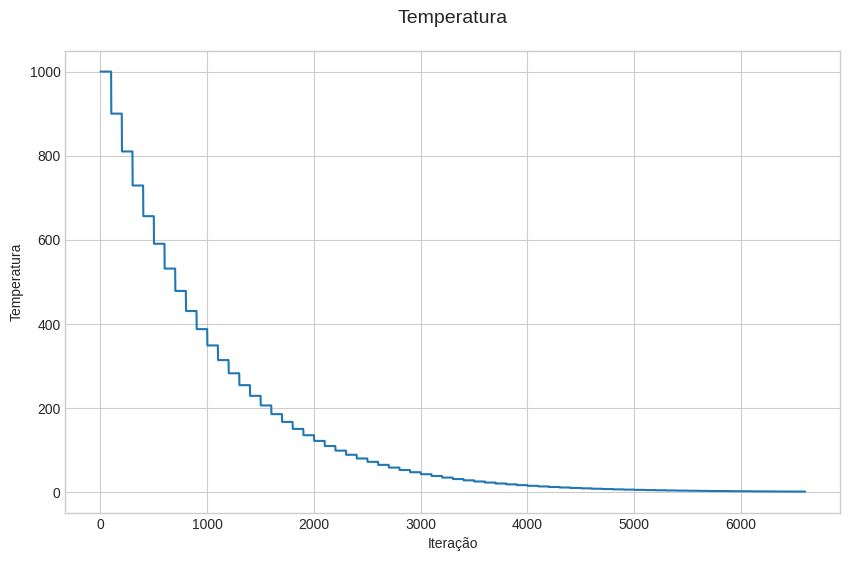

In [10]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(output['temperature'].keys(), output['temperature'].values())
ax.set_title('Temperatura', fontsize=14, pad=20)
ax.set_xlabel('Iteração')
ax.set_ylabel('Temperatura')